# Big Data and Iot Lab project
## YouTube spam comment predictor
### Md. Abdullah Ibna Harun || Sec:A(54)
### ID: 193-15-13426 || Email: abdullah15-13426@diu.edu.bd
Team name: Single Source

#Data Collection

### Import modules & dataset

In [1]:
!apt-get update

Hit:1 http://archive.ubuntu.com/ubuntu bionic InRelease
Get:2 http://archive.ubuntu.com/ubuntu bionic-updates InRelease [88.7 kB]
Get:3 http://security.ubuntu.com/ubuntu bionic-security InRelease [88.7 kB]
Get:4 https://cloud.r-project.org/bin/linux/ubuntu bionic-cran40/ InRelease [3,626 B]
Get:5 http://ppa.launchpad.net/c2d4u.team/c2d4u4.0+/ubuntu bionic InRelease [15.9 kB]
Ign:6 https://developer.download.nvidia.com/compute/machine-learning/repos/ubuntu1804/x86_64  InRelease
Get:7 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu1804/x86_64  InRelease [1,581 B]
Get:8 http://archive.ubuntu.com/ubuntu bionic-backports InRelease [83.3 kB]
Hit:9 https://developer.download.nvidia.com/compute/machine-learning/repos/ubuntu1804/x86_64  Release
Hit:10 http://ppa.launchpad.net/cran/libgit2/ubuntu bionic InRelease
Hit:11 http://ppa.launchpad.net/deadsnakes/ppa/ubuntu bionic InRelease
Get:12 http://ppa.launchpad.net/graphics-drivers/ppa/ubuntu bionic InRelease [21.3 kB]
Get:13 http

In [2]:
!apt-get install openjdk-8-jdk-headless -qq > /dev/null

In [3]:
!wget -q http://archive.apache.org/dist/spark/spark-3.1.1/spark-3.1.1-bin-hadoop3.2.tgz

In [4]:
!tar xf spark-3.1.1-bin-hadoop3.2.tgz

In [5]:
!pip install -q findspark

In [6]:
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-8-openjdk-amd64"
os.environ["SPARK_HOME"] = "/content/spark-3.1.1-bin-hadoop3.2"

In [7]:
pwd

'/content'

In [8]:
import findspark
findspark.init()
from pyspark.sql import SparkSession
spark = SparkSession.builder.master("local").appName("project").getOrCreate()
spark

In [9]:
#-------------- Youtube spam comment predictor --------------------#

# converting words into vectors to use as fetures to help in classification

#EDA packages
import pandas as pd
import numpy as np

In [10]:
# Ml packages for vectorization of text for feature extraction

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

In [11]:
# Visualization packages

import matplotlib.pyplot as plt
import seaborn as sns

### Data Input and Processing

In [12]:
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving Youtube01-Psy.csv to Youtube01-Psy.csv
Saving Youtube02-KatyPerry.csv to Youtube02-KatyPerry.csv
Saving Youtube03-LMFAO.csv to Youtube03-LMFAO.csv
Saving Youtube04-Eminem.csv to Youtube04-Eminem.csv
Saving Youtube05-Shakira.csv to Youtube05-Shakira.csv
User uploaded file "Youtube01-Psy.csv" with length 2354050 bytes
User uploaded file "Youtube02-KatyPerry.csv" with length 2134465 bytes
User uploaded file "Youtube03-LMFAO.csv" with length 2067789 bytes
User uploaded file "Youtube04-Eminem.csv" with length 2133569 bytes
User uploaded file "Youtube05-Shakira.csv" with length 2356330 bytes


In [13]:
#Dataset from Kaggle
df1 = spark.read.csv("Youtube01-Psy.csv", inferSchema= True ,header =True)

#load all dataset to mearge them
df2 = spark.read.csv("Youtube02-KatyPerry.csv",inferSchema= True ,header =True)
df3 = spark.read.csv("Youtube03-LMFAO.csv",inferSchema= True ,header =True)
df4= spark.read.csv("Youtube04-Eminem.csv",inferSchema= True ,header =True)
df5= spark.read.csv("Youtube05-Shakira.csv",inferSchema= True ,header =True)

df1.head()

Row(COMMENT_ID='z13kyh3gdnnzdvxjt04ch5xzwlvjyfujpik', AUTHOR='Lauralyn Karoll', DATE=None, CONTENT='"<a href=""https://www.facebook.com/groups/100877300245414/"">https://www.facebook.com/groups/100877300245414/</a>\ufeff"', CLASS='1')

### Data Visualization

<BarContainer object of 8 artists>

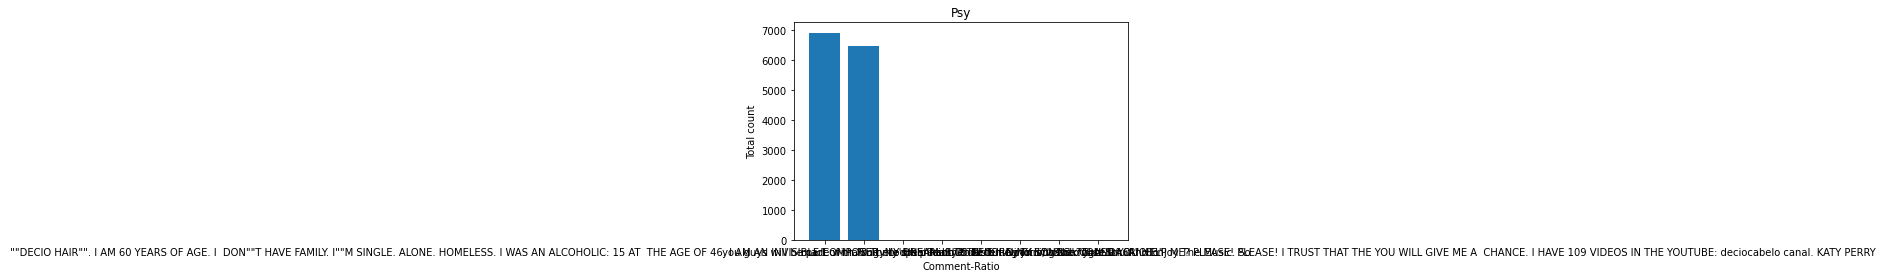

In [14]:
dfp1 = df1.toPandas()

data = dfp1['CLASS'].value_counts()
name= data.index
count = data.values 


plt.title("Psy")
plt.xlabel('Comment-Ratio')
plt.ylabel('Total count')

plt.bar(name,count)

<BarContainer object of 8 artists>

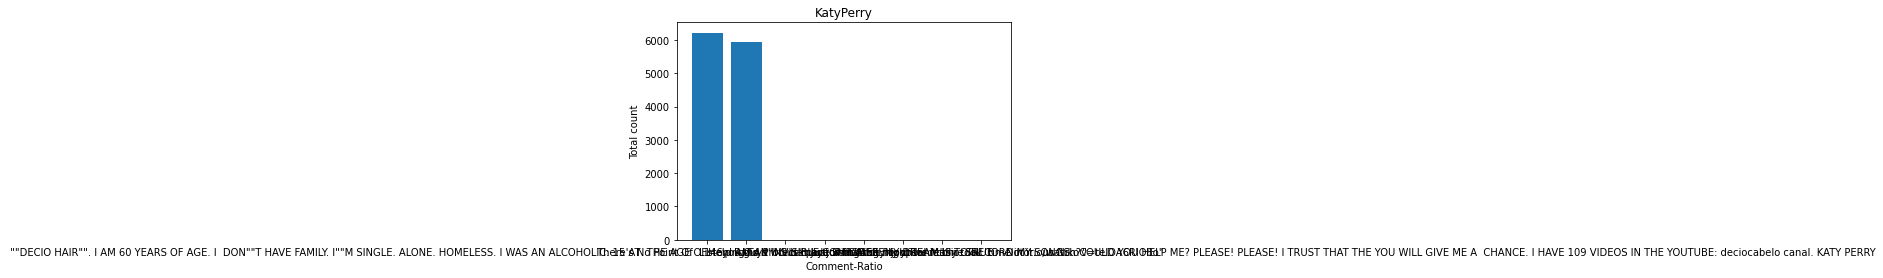

In [15]:
dfp2 = df2.toPandas()

data = dfp2['CLASS'].value_counts()
name= data.index
count = data.values 

plt.title("KatyPerry")
plt.xlabel('Comment-Ratio')
plt.ylabel('Total count')

plt.bar(name,count)

<BarContainer object of 8 artists>

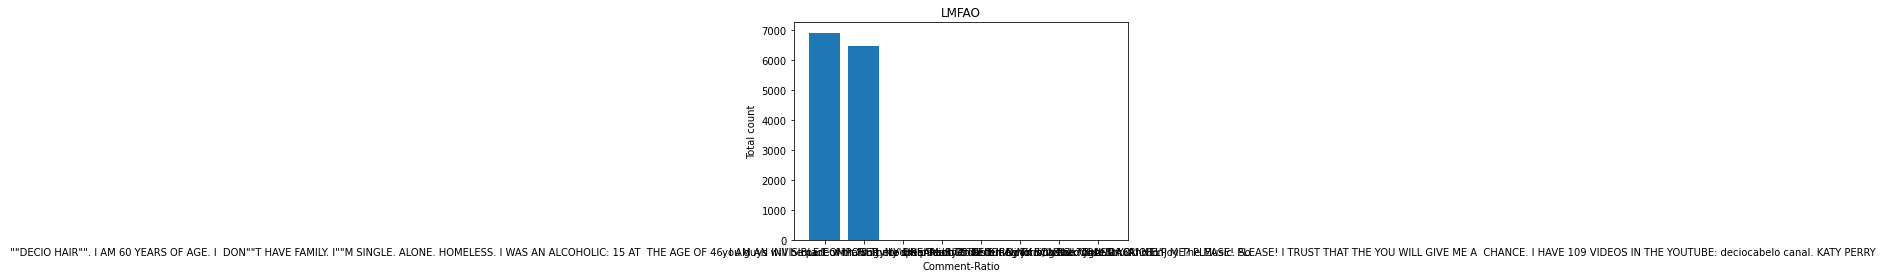

In [16]:
dfp3 = df3.toPandas()

data = dfp1['CLASS'].value_counts()
name= data.index
count = data.values 


plt.title("LMFAO")
plt.xlabel('Comment-Ratio')
plt.ylabel('Total count')

plt.bar(name,count)

<BarContainer object of 8 artists>

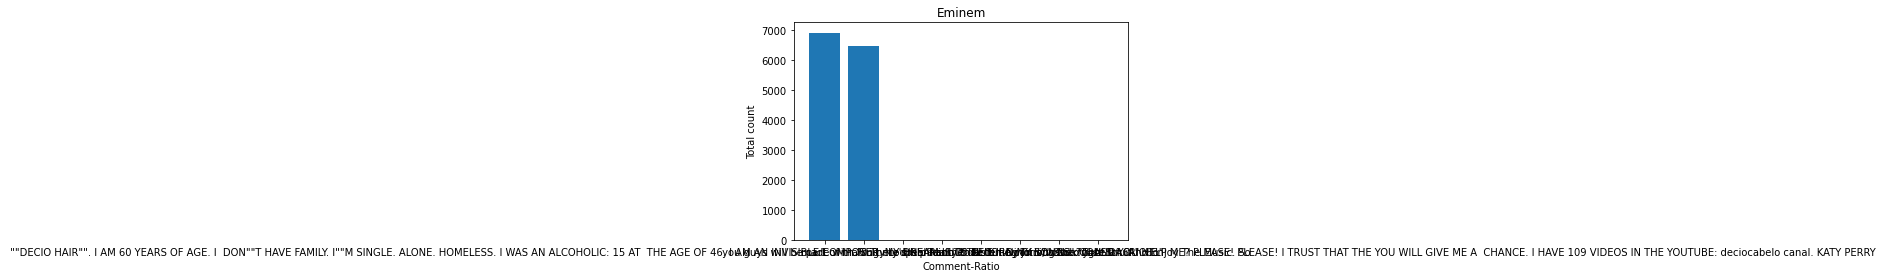

In [17]:
dfp4 = df4.toPandas()

data = dfp1['CLASS'].value_counts()
name= data.index
count = data.values 

plt.title("Eminem")
plt.xlabel('Comment-Ratio')
plt.ylabel('Total count')

plt.bar(name,count)

<BarContainer object of 8 artists>

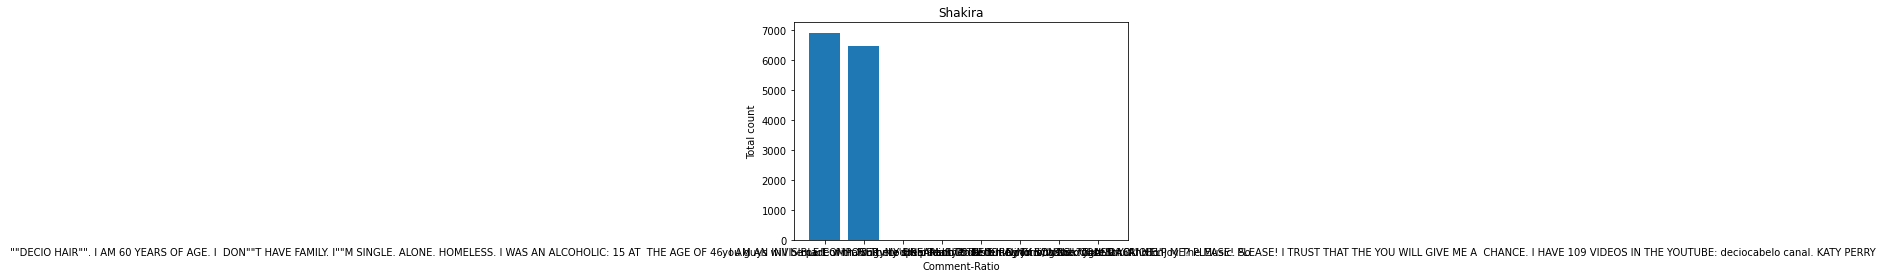

In [18]:
dfp5 = df5.toPandas()

data = dfp1['CLASS'].value_counts()
name= data.index
count = data.values 

plt.title("Shakira")
plt.xlabel('Comment-Ratio')
plt.ylabel('Total count')

plt.bar(name,count)

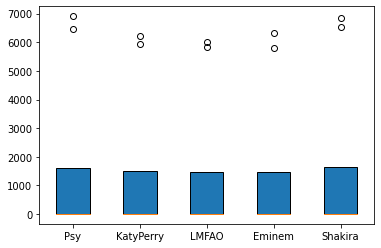

In [19]:
value1=df1.toPandas()['CLASS'].value_counts()
value2=df2.toPandas()['CLASS'].value_counts()
value3=df3.toPandas()['CLASS'].value_counts()
value4=df4.toPandas()['CLASS'].value_counts()
value5=df5.toPandas()['CLASS'].value_counts()
box_plot_data = [value1, value2, value3, value4, value5]

plt.boxplot(box_plot_data,patch_artist=True,labels = ['Psy' , 'KatyPerry','LMFAO','Eminem','Shakira'])
plt.show()

#  Pre-processing

### Data Merge

In [20]:
df1.show(6)

+--------------------+--------------------+--------------------+--------------------+-----+
|          COMMENT_ID|              AUTHOR|                DATE|             CONTENT|CLASS|
+--------------------+--------------------+--------------------+--------------------+-----+
|z13kyh3gdnnzdvxjt...|     Lauralyn Karoll|                null|"<a href=""https:...|    1|
|z12lhjtxlsisx55yu...|         Shirley Lim|                null|Take a look at th...|    1|
|z13hhxajgrnldjmn5...|TMCB production (...|                null|Check out our Cha...|    1|
|z12xurdj0qznephwg...|              Sylith|2015-05-28T21:50:...|Rihanna and Emine...|    0|
|z13isdtoikvzjlkij...|      nepaladventure|                null|Check out this pl...|    1|
|z13qf1qgcyigy14mx...|            Pugnsuit|2015-05-28T21:32:...|This song is abou...|    0|
+--------------------+--------------------+--------------------+--------------------+-----+
only showing top 6 rows



In [21]:
#printing total datasets
print("Comments               Columns ")
print("Dataframe 1 - ",df1.count(),"    ", len(df1.columns))
print("Dataframe 2 - ",df2.count(),"    ", len(df2.columns))
print("Dataframe 3 - ",df3.count(),"    ", len(df3.columns))
print("Dataframe 4 - ",df4.count(),"    ", len(df4.columns))
print("Dataframe 5 - ",df5.count(),"    ", len(df5.columns))

Comments               Columns 
Dataframe 1 -  13433      5
Dataframe 2 -  12195      5
Dataframe 3 -  11890      5
Dataframe 4 -  12169      5
Dataframe 5 -  13459      5


In [22]:
df1.printSchema()

root
 |-- COMMENT_ID: string (nullable = true)
 |-- AUTHOR: string (nullable = true)
 |-- DATE: string (nullable = true)
 |-- CONTENT: string (nullable = true)
 |-- CLASS: string (nullable = true)



In [23]:
# frames = [df1,df2,df3,df4,df5]

In [24]:
df_mearged=df1.unionByName(df2)
df_mearged=df_mearged.unionByName(df3)
df_mearged=df_mearged.unionByName(df4)
df_mearged=df_mearged.unionByName(df5)

In [25]:
print(df_mearged)

DataFrame[COMMENT_ID: string, AUTHOR: string, DATE: string, CONTENT: string, CLASS: string]


In [26]:
df_mearged.drop('COMMENT_ID','AUTHOR','DATE').show()

+--------------------+-----+
|             CONTENT|CLASS|
+--------------------+-----+
|"<a href=""https:...|    1|
|Take a look at th...|    1|
|Check out our Cha...|    1|
|Rihanna and Emine...|    0|
|Check out this pl...|    1|
|This song is abou...|    0|
|        like please﻿|    1|
|I love this song,...|    0|
|OMG that looks ju...|    0|
|"I shared my firs...|    1|
|Come and check ou...|    1|
|Check out this pl...|    1|
|HUH HYUCK HYUCK I...|    1|
|You exactly who u...|    0|
|Rihanna is absolu...|    0|
|Check out this vi...|    1|
|Don&#39;t love so...|    0|
|one of the BEST S...|    0|
|Check out this pl...|    1|
|Check out this vi...|    1|
+--------------------+-----+
only showing top 20 rows



### Null Remove And Save Merged Dataset 

In [27]:
# Get row count
rows = df_mearged.count()
print(f"DataFrame Rows count : {rows}")

DataFrame Rows count : 63146


In [28]:
frames = df_mearged.toPandas()
frames =frames.dropna()

In [29]:
# total size
frames.shape

(55733, 5)

In [30]:
# checking for consistent column name
df = frames.to_csv("YoutubeSpamMergedData02.csv")
df = pd.read_csv("YoutubeSpamMergedData02.csv")
df

,Unnamed: 0,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS
0,3,z12xurdj0qznephwg04cftq5rszgxdnq0xw0k,Sylith,2015-05-28T21:50:26.114000,Rihanna and Eminem together are unstoppable.﻿,0
1,5,z13qf1qgcyigy14mx223iv2yqxb5ebze4,Pugnsuit,2015-05-28T21:32:08.714000,This song is about Rape and Cheating <br /...,0
2,7,z12fcjxowubrsnwx104cftlgcpfzw5uwbug0k,Izana,2015-05-28T20:46:16.348000,"I love this song, can&#39;t believe it was 5 y...",0
3,8,z12yg3dp5kf0hnbdj23aftm4iovygt32c,Daniel Klous,2015-05-28T20:24:21.778000,OMG that looks just like a piece of the mirror...,0
4,13,z12litdrrkzmg51kn23ghl2rctvttp0c4,LIL TEZ,2015-05-28T20:11:52.781000,"You exactly who u want to be,watching your fav...",0
...,...,...,...,...,...,...
55728,63141,_2viQ_Qnc6-LyNEXRld9VERRpRICrMPNxpnGjL8ZsF4,DJ ROY,2013-08-02T21:02:09.931000,Hey youtubers... I really appreciate all of yo...,1
55729,63142,_2viQ_Qnc69zyetF6GsHRzYGyXl4u5kg0Sm-nP-pupI,Shadrach Grentz,2013-08-02T03:15:46.914000,Hey Music Fans I really appreciate any of you ...,1
55730,63143,_2viQ_Qnc699u36gNm3NRoq1quIaJWRNrftGEEZM3J4,Shadrach Grentz,2013-08-01T21:43:52.122000,Hey Music Fans I really appreciate any of you ...,1
55731,63144,_2viQ_Qnc68LqKGb40V2ImKQYcp1ZqpHrCCMFqMCcA4,Shadrach Grentz,2013-08-01T20:39:15.325000,Hey Music Fans I really appreciate any of you ...,1


In [31]:
#data size
df.size

334398

In [32]:
# checking data types
df.dtypes

Unnamed: 0     int64
COMMENT_ID    object
AUTHOR        object
DATE          object
CONTENT       object
CLASS         object
dtype: object

In [33]:
## working with text content
df_data = df[['CONTENT','CLASS']]
# to see those values content =  comments && class = true/false
df_data

,CONTENT,CLASS
0,Rihanna and Eminem together are unstoppable.﻿,0
1,This song is about Rape and Cheating <br /...,0
2,"I love this song, can&#39;t believe it was 5 y...",0
3,OMG that looks just like a piece of the mirror...,0
4,"You exactly who u want to be,watching your fav...",0
...,...,...
55728,Hey youtubers... I really appreciate all of yo...,1
55729,Hey Music Fans I really appreciate any of you ...,1
55730,Hey Music Fans I really appreciate any of you ...,1
55731,Hey Music Fans I really appreciate any of you ...,1


In [34]:
# to see new dataset columns
df_data.columns

Index(['CONTENT', 'CLASS'], dtype='object')

In [35]:
# inserting data inn x,y for visualization
df_x = df_data['CONTENT']
df_y = df_data['CLASS']

# Feature Selection and Extraction

### Feature Selection

In [36]:
### Feature Extraction From Text

#1 CountVectorizer
#2 TfidfVectorizer

cv = CountVectorizer()

ex = cv.fit_transform(["Great song but check this out","What is this song"])

In [37]:
# convertion to arry
ex.toarray()

array([[1, 1, 1, 0, 1, 1, 1, 0],
       [0, 0, 0, 1, 0, 1, 1, 1]])

In [38]:
# gettingh feature name
cv.get_feature_names()

/usr/local/lib/python3.8/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


['but', 'check', 'great', 'is', 'out', 'song', 'this', 'what']

### Feature Extraction and Feature Engineering

In [39]:
# extrat feature with CountVectorizer
corpus = df_x
cv = CountVectorizer()
X = cv.fit_transform(corpus)

In [40]:
# convertingf x to an array
X.toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [41]:
# get the feature names
cv.get_feature_names()

['00',
 '000',
 '002',
 '018',
 '02',
 '034',
 '04',
 '05',
 '053012',
 '0687119038',
 '08',
 '0cb8qfjaa',
 '0d878a889c',
 '0dbhjzdw0lbsjbi40gxm0d0p5krhv8xinqli53__wqbahs8zx4mjhw5vwrkpxfoeks',
 '0laviqu2b',
 '10',
 '100',
 '1000',
 '10000000',
 '1000000000',
 '100000415527985',
 '100005244783212',
 '100007085325116',
 '10001',
 '101721377578919894134',
 '10200253113705769',
 '1030',
 '104999962146104962510',
 '10626048',
 '10626835',
 '106865403',
 '107297364',
 '1073741825',
 '1073741828',
 '1073741830',
 '1073741943',
 '108k',
 '10b35481',
 '11',
 '1111',
 '1111111111111111111',
 '111719098841907',
 '111982027348137311818',
 '112720997191206369631',
 '11cpwb',
 '11th',
 '12',
 '123',
 '124',
 '124923004',
 '126',
 '127',
 '128gb',
 '12year',
 '13',
 '13017194',
 '131275322914',
 '131338190916',
 '1340488',
 '1340489',
 '1340490',
 '1340491',
 '1340492',
 '1340493',
 '1340494',
 '1340499',
 '1340500',
 '1340502',
 '1340503',
 '1340504',
 '1340517',
 '1340518',
 '1340519',
 '1340520',


# Classification

### Model Building

In [42]:
# module building
from sklearn.model_selection import train_test_split

In [43]:
#training
X_train,X_test,y_train,y_test = train_test_split(X,df_y,test_size=0.33,random_state = 42)

In [44]:
X_train

<37341x3846 sparse matrix of type '<class 'numpy.int64'>'
	with 434396 stored elements in Compressed Sparse Row format>

### Analyze and apply algorithms.

In [45]:
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
KNNC = KNeighborsClassifier(n_neighbors=101)
KNNC.fit(X_train,y_train)
print(f"Train Accuracy of model {KNNC.score(X_train,y_train)*100} %")
# acuracy of the model
print(f"Test Accuracy of model {KNNC.score(X_test,y_test)*100} %")

Train Accuracy of model 90.30020620765379 %
Test Accuracy of model 89.91409308394954 %


In [46]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
dtc = DecisionTreeClassifier(random_state=101)
dtc.fit(X_train,y_train)
print(f"Train Accuracy of model {dtc.score(X_train,y_train)*100} %")
# acuracy of the model
print(f"Test Accuracy of model {dtc.score(X_test,y_test)*100} %")

Train Accuracy of model 100.0 %
Test Accuracy of model 100.0 %


In [47]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
Rfc= RandomForestClassifier(random_state=101)
Rfc.fit(X_train,y_train)
print(f"Train Accuracy of model {Rfc.score(X_train,y_train)*100} %")
# acuracy of the model
print(f"Test Accuracy of model {Rfc.score(X_test,y_test)*100} %")

Train Accuracy of model 100.0 %
Test Accuracy of model 100.0 %


In [48]:
from sklearn.svm import SVC
from pandas.core.common import random_state
svc = SVC(random_state=101)
svc.fit(X_train,y_train)
print(f"Train Accuracy of model {svc.score(X_train,y_train)*100} %")
# acuracy of the model
print(f"Test Accuracy of model {svc.score(X_test,y_test)*100} %")

Train Accuracy of model 100.0 %
Test Accuracy of model 100.0 %


In [49]:
# Naive Bayes Classifire
from sklearn.naive_bayes import MultinomialNB
clf = MultinomialNB()
clf.fit(X_train,y_train)
print(f"Train Accuracy of model {clf.score(X_train,y_train)*100} %")
# acuracy of the model
print(f"Test Accuracy of model {clf.score(X_test,y_test)*100} %")

Train Accuracy of model 98.41193326370478 %
Test Accuracy of model 98.41779034362766 %


#  Comparison of results

## Predict & Output

### Confusion Matrix

/usr/local/lib/python3.8/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function plot_confusion_matrix is deprecated; Function `plot_confusion_matrix` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: ConfusionMatrixDisplay.from_predictions or ConfusionMatrixDisplay.from_estimator.
  warnings.warn(msg, category=FutureWarning)


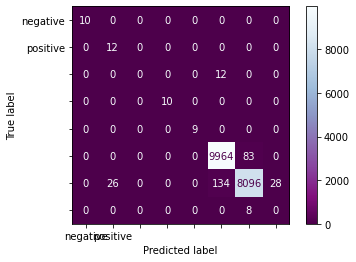

In [50]:
from sklearn.metrics import plot_confusion_matrix
import matplotlib.pyplot as plt
plot_confusion_matrix(clf,X_test,y_test,cmap='BuPu_r',display_labels=['negative','positive'])
plt.show()

In [51]:
## predict with the model
clf.predict(X_test)

array(['0', '1', '1', ..., '1', '0', '0'], dtype='<U338')


### Testing

In [52]:
# a simple prediction 1
comment = ["Check this out"]
vect = cv.transform(comment).toarray()
vect

array([[0, 0, 0, ..., 0, 0, 0]])

In [53]:
clf.predict(vect)

array(['1'], dtype='<U338')

In [54]:
class_dict = {"Not Spam":0,"Spam":1}
class_dict.values()

dict_values([0, 1])

In [55]:
if (clf.predict(vect) == '1'):
    print("Spam")
else:
    print("Not Spam")

Spam


In [56]:
# simple Prerdiction 2
comment1 = [str(input())]
vect = cv.transform(comment1).toarray()
print(clf.predict(vect))
if clf.predict(vect) == '1':
    print("Spam")
else:
    print("Not Spam")

This song is about Rape and Cheating 
['0']
Not Spam


### Save The model

In [57]:
import pickle as pk

In [58]:
naivebayesML = open("YtbSpam_model.pkl","wb")
pk.dump(clf,naivebayesML)
naivebayesML.close()
## load the model

ytb_model = open("YtbSpam_model.pkl","rb")
new_model = pk.load(ytb_model)
new_model

MultinomialNB()

# Thak You :)
